# TPI - Entrega 3: Visualizacion de Datos
## Comision 13 (Grupo M) | Integrante: Gustavo Farias

**Lenguaje utilizado:** Python (pandas, matplotlib, seaborn).

**Dataset:** reservas hoteleras (City Hotel y Resort Hotel).
**Problema:** comprender las cancelaciones de reservas (`is_canceled`) para reducir su tasa y mejorar la planificacion.


In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo base para todos los graficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (9, 6)

# Carga del dataset original
df_original = pd.read_csv('hotel booking TPI grupo M.csv')
print("Dataset original cargado:", df_original.shape)

Dataset original cargado: (25000, 32)


In [76]:
# Copia
df = df_original.copy()

# 1. children: imputo el unico faltante y convierto a entero
df['children'] = df['children'].fillna(0).astype(int)

# 2. Unifico codigos de pais
df['country'] = df['country'].replace('CN', 'CHN')

# 3. Parseo de fecha de llegada a datetime
df['arrival_date'] = pd.to_datetime(df['arrival_date'], errors='coerce')

# 4. Variables derivadas usadas en las visualizaciones
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['lead_time_segment'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, 1000],
    labels=['Ultima hora (0-7)', 'Corto (8-30)', 'Mediano (31-90)', 'Largo (>90)']
)
df['arrival_month'] = df['arrival_date'].dt.to_period('M').astype(str)

print("Preparacion minima aplicada. Filas:", df.shape[0])
df.head(3)

Preparacion minima aplicada. Filas: 25000


,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,total_nights,lead_time_segment,arrival_month
0,HB-000924,Resort Hotel,1,118,2023,August,31,6,2023-08-06,0,...,240.0,NaN,0,Transient,120.6,0,0,3,Largo (>90),2023-08
1,HB-004486,Resort Hotel,1,20,2024,March,12,20,2024-03-20,2,...,240.0,NaN,0,Transient,60.0,0,2,3,Corto (8-30),2024-03
2,HB-112184,City Hotel,0,28,2025,May,20,18,2025-05-18,0,...,9.0,NaN,0,Transient,190.0,0,1,3,Corto (8-30),2025-05


## Visualizacion 1: Cancelaciones segun tipo de hotel

**Pregunta de analisis:** La proporcion de reservas canceladas difiere entre el City Hotel y el Resort Hotel?

**Porque este grafico:** Uso barras apiladas al 100% porque los dos hoteles tienen tamaños muy distintos (City 16.522 vs Resort 8.478 reservas). Comparar cantidades absolutas seria engañoso; normalizar al 100% permite comparar la incidencia real de cancelacion. El segmento de interes (Cancelada) se apoya en la base del eje para leerse con precision, y se incluye el valor exacto en cada segmento.

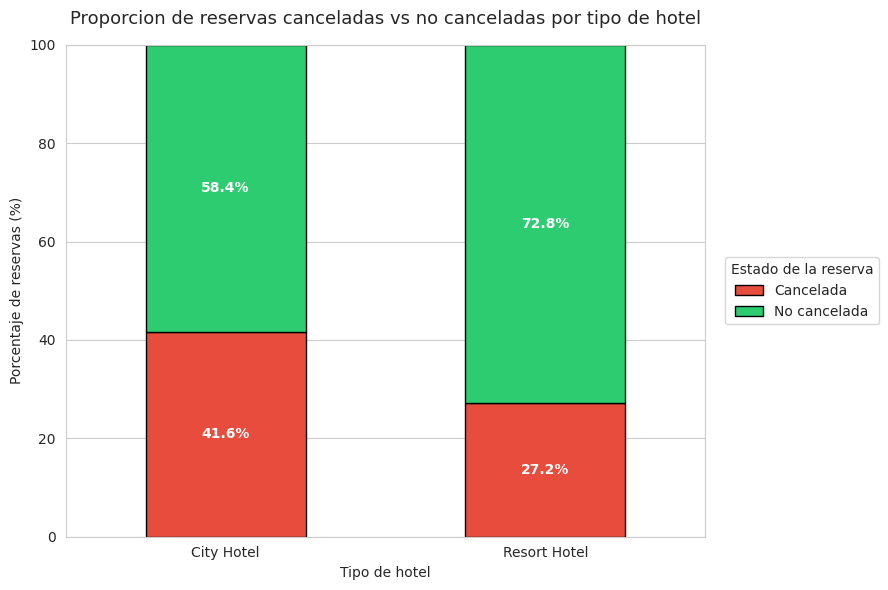

In [77]:
# Proporciones de cancelacion por hotel
prop = df.groupby(['hotel', 'is_canceled']).size().unstack(fill_value=0)
prop_pct = prop.div(prop.sum(axis=1), axis=0) * 100
prop_pct = prop_pct[[1, 0]]  # Cancelada en la base
prop_pct.columns = ['Cancelada', 'No cancelada']

ax = prop_pct.plot(
    kind='bar', stacked=True,
    color=['#e74c3c', '#2ecc71'], edgecolor='black'
)

# Etiquetas con el porcentaje exacto dentro de cada segmento
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

ax.set_title('Proporcion de reservas canceladas vs no canceladas por tipo de hotel', fontsize=13, pad=15)
ax.set_xlabel('Tipo de hotel')
ax.set_ylabel('Porcentaje de reservas (%)')
ax.set_ylim(0, 100)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Estado de la reserva', loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

**Interpretacion:** El City Hotel presenta una tasa de cancelacion notablemente mayor (41,6 %) que el Resort Hotel (27,2 %), una diferencia de unos 14 puntos porcentuales. En ambos hoteles la mayoria de las reservas se concretan, pero el perfil urbano muestra mucha mas volatilidad. Esto sugiere que el City Hotel deberia priorizar politicas de deposito y recordatorios preventivos, mientras que el resort, con reservas mas firmes (perfil vacacional), podria enfocarse en otro apalancamiento.

## Visualizacion 2: Anticipacion de la reserva (lead_time) y cancelacion

**Pregunta de analisis:** Las reservas canceladas se hicieron con mas o menos anticipacion que las efectivas?

**Porque este grafico:** Elijo `lead_time` (dias entre la reserva y la llegada) como variable cuantitativa relevante. Uso un diagrama de caja (boxplot) porque permite comparar la distribucion completa (mediana, cuartiles y valores atipicos) de una variable continua entre dos grupos (cancelada vs no cancelada), algo que un simple promedio ocultaria.

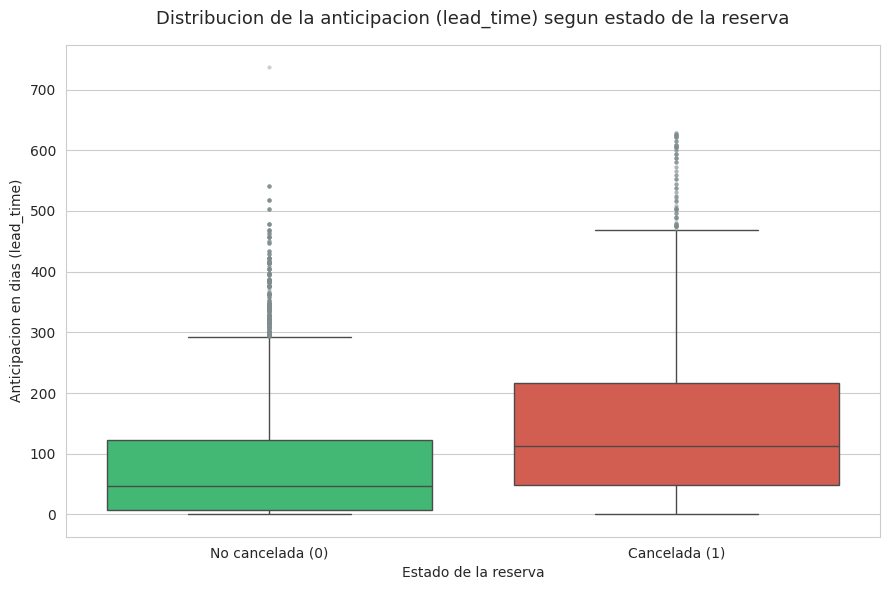

Medianas de lead_time:
is_canceled
0     46.0
1    113.0
Name: lead_time, dtype: float64


In [83]:
fig, ax = plt.subplots()

# Columna para el eje X
df['estado'] = df['is_canceled'].map({0: 'No cancelada (0)', 1: 'Cancelada (1)'})

# Orden y colores: verde = no cancelada y rojo = cancelada
sns.boxplot(
    data=df, x='estado', y='lead_time',
    hue='estado',
    order=['No cancelada (0)', 'Cancelada (1)'],
    hue_order=['No cancelada (0)', 'Cancelada (1)'],
    palette=['#2ecc71', '#e74c3c'],
    legend=False, ax=ax,
    flierprops=dict(marker='o', markersize=3,
                    markerfacecolor='#7f8c8d',
                    markeredgecolor='none', alpha=0.4)
)

ax.set_title('Distribucion de la anticipacion (lead_time) segun estado de la reserva', fontsize=13, pad=15)
ax.set_xlabel('Estado de la reserva')
ax.set_ylabel('Anticipacion en dias (lead_time)')
plt.tight_layout()
plt.show()

print("Medianas de lead_time:")
print(df.groupby('is_canceled')['lead_time'].median())

**Interpretacion:** Las reservas canceladas tienen una mediana de anticipacion claramente mayor que las efectivas. Esto indica que cuanto mas lejos se reserva, mayor es la probabilidad de que los planes cambien y la reserva se cancele. Las reservas de ultima hora tienden a ser mas firmes. Ademas, el grupo de canceladas muestra mayor dispersion y mas valores atipicos altos, lo que refuerza la relacion entre larga anticipacion e incertidumbre.

## Visualizacion 3: Tipo de deposito y cancelacion a lo largo del tiempo

**Pregunta de analisis:** Como evoluciona la tasa de cancelacion mes a mes y que papel juega el tipo de deposito (sin deposito, reembolsable, no reembolsable)?

**Porque este grafico:** Combino una dimension temporal (mes de llegada) con una categórica (deposit_type) usando lineas por categoria. El grafico de lineas es ideal para mostrar evolucion en el tiempo, y el color distingue el efecto del deposito. Esto agrega una tercera dimension a la pregunta de cancelacion, yendo mas alla de las dos visualizaciones anteriores.

Reservas por tipo de deposito:
deposit_type
No Deposit    21912
Non Refund     3051
Refundable       37
Name: count, dtype: int64



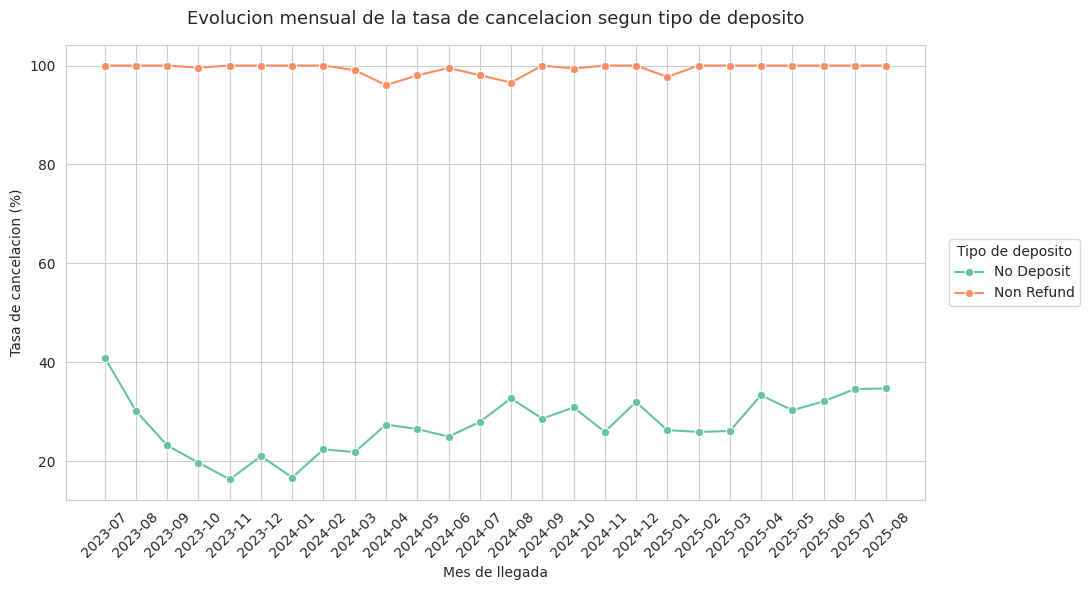

In [81]:
# Volumen de cada categoria de deposito: condiciona la confiabilidad de las tasas mensuales
print("Reservas por tipo de deposito:")
print(df['deposit_type'].value_counts())
print()

# 'Refundable' tiene solo 37 reservas: con 1-2 casos por mes, su tasa mensual seria 0% o 100%
# y no aportaria lectura fiable. Se la excluye del grafico y se documenta en la interpretacion.
depositos = ['No Deposit', 'Non Refund']

tasa = (df[df['deposit_type'].isin(depositos)]
          .groupby(['arrival_month', 'deposit_type'])['is_canceled']
          .mean()
          .mul(100)
          .reset_index(name='tasa_cancelacion'))

fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(
    data=tasa, x='arrival_month', y='tasa_cancelacion',
    hue='deposit_type', marker='o', palette='Set2', ax=ax
)

ax.set_title('Evolucion mensual de la tasa de cancelacion segun tipo de deposito', fontsize=13, pad=15)
ax.set_xlabel('Mes de llegada')
ax.set_ylabel('Tasa de cancelacion (%)')
ax.legend(title='Tipo de deposito', loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretacion:** El patron dominante es contraintuitivo: las reservas con deposito "Non Refund" presentan tasas de cancelacion cercanas al 100 % en todos los meses, mientras que las "No Deposit" (que concentran la mayoria del volumen) oscilan entre el 16 % y el 41 %, con cierta estacionalidad. Que las reservas no reembolsables aparezcan casi siempre canceladas sugiere que el campo deposit_type estaria registrando la condicion del deposito asociada al desenlace de la reserva (el deposito se pierde al cancelar), y no una politica elegida al reservar; por eso no debe leerse como que el deposito no reembolsable genere cancelaciones. La categoria "Refundable" (37 casos) se excluyo del grafico porque con 1 o 2 reservas por mes sus tasas mensuales (0% o 100%) no son estadisticamente interpretables.

## Sintesis y cierre

### Tres hallazgos obtenidos
1. **El tipo de hotel influye en la cancelacion:** el City Hotel cancela cerca del 42% de sus reservas frente al 28% del Resort Hotel, reflejando mayor volatilidad del perfil urbano frente al vacacional.
2. **La anticipacion se asocia a la cancelacion:** las reservas canceladas se hicieron con mas dias de antelación (mayor mediana de `lead_time`), lo que indica que reservar con mucha antelación aumenta la incertidumbre.
3. **El campo deposit_type exige una lectura cuidadosa:** "Non Refund" aparece casi exclusivamente en reservas canceladas (100 % todos los meses), lo que sugiere un efecto de registro (el deposito se clasifica segun el desenlace) mas que una palanca de gestion. La variabilidad realmente util para el negocio esta en "No Deposit", cuya tasa mensual oscila entre 16% y 41% con un patron estacional marcado.

### Limitacion o precaucion
Todas estas relaciones son **asociaciones observadas, no causalidades demostradas**. Un grafico bivariado o trivariado no controla variables de confusion: por ejemplo, la mayor cancelacion del City Hotel podria explicarse parcialmente porque alli se concentran mas reservas sin deposito o de mayor anticipacion, y no necesariamente por ser un hotel urbano. Antes de elaborar conclusiones amplias o tomar decisiones de negocio (como cambiar politicas de deposito), corresponde validar estos hallazgos con analisis multivariados o modelos que aislen el efecto de cada factor.